# 4. One firm is enough, and the volatility law

From here on the model is the demographic one at the reference point: $\alpha=2.5$, $\sigma=1.70$, $D=0.1$, $C=200$,
$\mu=-1.76$. The theory tests use two stored economies with $N=16000$ (`economy.reference_economy`; burn-in 100, window 480,
samples every 0.5 = one year). A missing trajectory is simulated on first use (about an hour each).

The one-firm equation of notebook 01,

$$dS_i=S_i\big[\Phi_i(t)-S_i\big]dt+\sqrt{DS_i}\,dW_i+O(N^{-1/2}),$$

is exact. Its content is that the field can be treated as **given**: that a firm's own noise does not feed back on its
field through the network.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import economy as eco
from economy import lives, zeta_bins, DATA, FIGURES, tidy

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})

## The reduction

Store the fields $\Phi_i(t)$ of the two economies; integrate the one-firm equation for every node with its measured field
(linear between samples), fresh noise, exit at 0 and a newborn at $D$, from the full model's sizes at the first sample;
compare the life panels.

n_min   zeta_1 full  one firm    zeta_q/zeta_1 full    one firm
    2   0.179        0.186       2.42 3.97 5.51      2.41 3.96 5.54
    5   0.209        0.217       1.94 2.74 3.36      1.94 2.76 3.42
   10   0.222        0.230       1.82 2.42 2.82      1.82 2.42 2.83
   20   0.254        0.265       1.80 2.42 2.88      1.81 2.43 2.89
exits per node per unit time: full 0.621, one firm 0.609


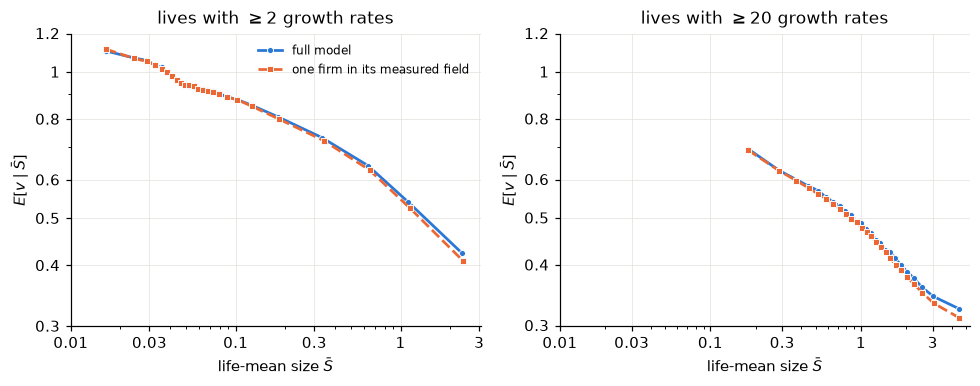

In [2]:
def surrogate(S_full, Phi, seed, dt=0.01):
    rng = np.random.default_rng(100 + seed)
    N, T = S_full.shape
    per = int(round(eco.DT / dt))
    S, life = S_full[:, 0].copy(), np.zeros(N, np.int64)
    out_S, out_L = [S.copy()], [life.copy()]
    for k in range(T - 1):
        for j in range(per):
            ph = Phi[:, k] + (Phi[:, k + 1] - Phi[:, k]) * j / per
            S = S + S * (ph - S) * dt + np.sqrt(eco.D * np.maximum(S, 0) * dt) * rng.standard_normal(N)
            dead = S <= 0
            if dead.any():
                S[dead] = eco.D
                life[dead] += 1
        out_S.append(S.copy())
        out_L.append(life.copy())
    return np.array(out_S).T, np.array(out_L).T


def panel(S, L):
    lv = lives(S, L)
    return np.array([x[0] for x in lv]), np.array([x[1] for x in lv]), np.array([x[2] for x in lv])


def reduction(path=DATA / "demographic" / "reduction.npz"):
    if not path.exists():
        res, save = {}, {}
        for seed in eco.SEEDS:
            S_full, L_full, _, _, Phi = eco.reference_economy(seed)
            L_full = L_full - L_full[:, :1]
            S_sur, L_sur = surrogate(S_full, Phi, seed)
            res[seed] = {"full": panel(S_full, L_full), "sur": panel(S_sur, L_sur)}
            save[f"exits{seed}"] = (L_full[:, -1].mean() / eco.TOBS, L_sur[:, -1].mean() / eco.TOBS)
        save["exits"] = np.array([save.pop(f"exits{s}") for s in eco.SEEDS])
        for nm in (2, 5, 10, 20):
            for which in ("full", "sur"):
                Sb, v, n = (np.concatenate(x) for x in zip(*(res[s][which] for s in eco.SEEDS)))
                sel = n >= nm
                save[f"zeta_{which}_{nm}"] = zeta_bins(Sb[sel], v[sel])[0]
                P = np.array_split(np.argsort(Sb[sel]), 25)
                save[f"curve_{which}_{nm}"] = np.array([[Sb[sel][p].mean() for p in P], [v[sel][p].mean() for p in P]])
        np.savez(path, **save)
    return np.load(path)


R = reduction()
print("n_min   zeta_1 full  one firm    zeta_q/zeta_1 full    one firm")
for nm in (2, 5, 10, 20):
    zf, zs = R[f"zeta_full_{nm}"], R[f"zeta_sur_{nm}"]
    print(f"{nm:5d}   {zf[0]:.3f}        {zs[0]:.3f}       {' '.join(f'{x:.2f}' for x in zf[1:] / zf[0])}      "
          f"{' '.join(f'{x:.2f}' for x in zs[1:] / zs[0])}")
ex = R["exits"]
print(f"exits per node per unit time: full {ex[:, 0].mean():.3f}, one firm {ex[:, 1].mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for k, nm in enumerate((2, 20)):
    for which, c, mk, lab in (("full", "#2a78d6", "o-", "full model"), ("sur", "#eb6834", "s--", "one firm in its measured field")):
        x, y = R[f"curve_{which}_{nm}"]
        ax[k].loglog(x, y, mk, color=c, lw=1.8, ms=4, mec="white", mew=0.6, label=lab)
    ax[k].set(title=rf"lives with $\geq{nm}$ growth rates", xlabel=r"life-mean size $\bar S$", ylabel=r"$E[v\mid\bar S]$")
    tidy(ax[k], [0.01, 0.03, 0.1, 0.3, 1, 3], [0.3, 0.4, 0.5, 0.6, 0.8, 1, 1.2])
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "demographic_reduction.png", dpi=200)

The exponents agree to about $0.01$, the ratios to $0.06$ and the exit rates to $2\%$ for every minimum life length.
**The theory of the size–volatility statistics is a one-firm problem, given the statistics of the field.**

## The field law

The HDMFT field is $\Phi(t)=1-\bar f(t)+\mu\kappa\bar B+\sigma\sqrt\kappa\,\xi(t)$ (notebook 02): its mean falls linearly in the
relative degree $\kappa=k/C$ under competition, and its amplitude grows as $\sqrt\kappa$. Per node over the window: the time
mean $\bar\Phi_i$ and the time standard deviation $f_i$.

32000 nodes, relative degree 0.29..98.4
  kappa  <Phibar> sd Phibar  median f    <S>
   0.38     0.535     1.569     1.234   1.02
   0.41     0.406     1.654     1.275   0.98
   0.44     0.284     1.737     1.318   0.95
   0.49     0.320     1.820     1.404   1.01
   0.54     0.197     1.960     1.485   1.01
   0.61     0.077     2.081     1.569   1.00
   0.72    -0.014     2.264     1.712   1.05
   0.87    -0.279     2.462     1.929   1.05
   1.17    -0.799     2.951     2.228   1.04
   2.03    -2.311     3.889     2.982   0.94
amplitude f ~ kappa^0.54 (theory 0.5);  standardised Phibar within classes: skewness -0.30, excess kurtosis +2.03;  field correlation time (1/e) 4.5


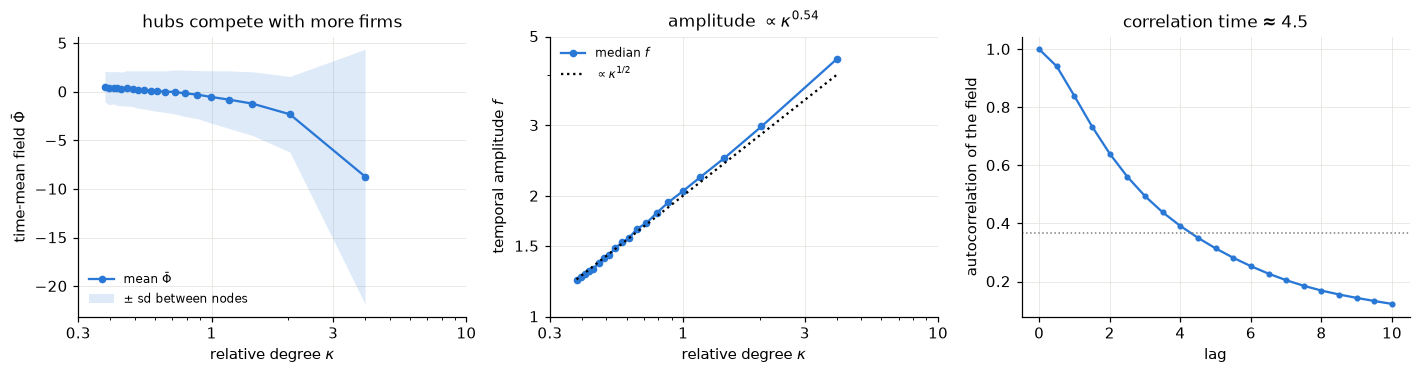

In [3]:
K, PB, F, SM, AC = [], [], [], [], []
for seed in eco.SEEDS:
    S, L, deg, _, Phi = eco.reference_economy(seed)
    K.append(deg / deg.mean()); PB.append(Phi.mean(1)); F.append(Phi.std(1)); SM.append(S.mean(1))
    x = Phi - Phi.mean(1, keepdims=True)
    AC.append([np.mean(np.sum(x[:, l:] * x[:, :x.shape[1] - l], 1) / np.sum(x * x, 1)) for l in range(21)])
kap, pb, f, sm = map(np.concatenate, (K, PB, F, SM))
ac = np.mean(AC, 0)
edges = np.quantile(kap, np.linspace(0, 1, 21))
b = np.clip(np.digitize(kap, edges[1:-1]), 0, 19)
J = [j for j in range(20) if (b == j).sum() > 50]
kc = np.array([np.median(kap[b == j]) for j in J])
mpb, vpb = np.array([pb[b == j].mean() for j in J]), np.array([pb[b == j].var() for j in J])
mf, msm = np.array([np.median(f[b == j]) for j in J]), np.array([sm[b == j].mean() for j in J])
h = np.polyfit(np.log(kc), np.log(mf), 1)[0]
z = np.concatenate([(pb[b == j] - pb[b == j].mean()) / pb[b == j].std() for j in J])
tau = 0.5 * np.argmax(ac < np.exp(-1))
print(f"{kap.size} nodes, relative degree {kap.min():.2f}..{kap.max():.1f}")
print(f"{'kappa':>7} {'<Phibar>':>9} {'sd Phibar':>9} {'median f':>9} {'<S>':>6}")
for j in range(0, len(J), 2):
    print(f"{kc[j]:7.2f} {mpb[j]:9.3f} {np.sqrt(vpb[j]):9.3f} {mf[j]:9.3f} {msm[j]:6.2f}")
print(f"amplitude f ~ kappa^{h:.2f} (theory 0.5);  standardised Phibar within classes: skewness {stats.skew(z):+.2f}, "
      f"excess kurtosis {stats.kurtosis(z):+.2f};  field correlation time (1/e) {tau:.1f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(kc, mpb, "o-", color="#2a78d6", ms=4, label=r"mean $\bar\Phi$")
ax[0].fill_between(kc, mpb - np.sqrt(vpb), mpb + np.sqrt(vpb), color="#2a78d6", alpha=0.15, lw=0, label="± sd between nodes")
ax[0].set(xscale="log", xlabel=r"relative degree $\kappa$", ylabel=r"time-mean field $\bar\Phi$", title="hubs compete with more firms")
ax[1].loglog(kc, mf, "o-", color="#2a78d6", ms=4, label="median $f$")
ax[1].loglog(kc, mf[len(J) // 2] * (kc / kc[len(J) // 2]) ** 0.5, ":", color="black", label=r"$\propto\kappa^{1/2}$")
ax[1].set(xlabel=r"relative degree $\kappa$", ylabel="temporal amplitude $f$", title=rf"amplitude $\propto\kappa^{{{h:.2f}}}$")
ax[2].plot(0.5 * np.arange(ac.size), ac, "o-", color="#2a78d6", ms=3)
ax[2].axhline(np.exp(-1), color="grey", ls=":", lw=1)
ax[2].set(xlabel="lag", ylabel="autocorrelation of the field", title=f"correlation time ≈ {tau:.1f}")
for a, yt in zip(ax, (None, [1, 1.5, 2, 3, 5], None)):
    if a.get_legend_handles_labels()[0]:
        a.legend(frameon=False, fontsize=8)
    tidy(a, [0.3, 1, 3, 10] if a is not ax[2] else None, yt)
plt.tight_layout()

A node's mean field falls with its degree (hubs compete with more firms); its temporal amplitude grows close to
$\kappa^{1/2}$; within a degree class the mean field is nearly symmetric (skewness $-0.3$) but fatter-tailed than a
Gaussian. The degree therefore sets both how long a firm
lives and how strongly it is shaken while alive; the second effect drives the multiscaling (notebook 05).

## The volatility law

In logs the one-firm equation reads $d\ln S=(\Phi-S-D/2S)\,dt+\sqrt{D/S}\,dW$. Write $\ln S=y_F+\delta$, where $y_F$ solves the
noise-free equation $\dot y_F=\Phi-e^{y_F}$ from the same initial size. To linear order $\delta$ is an Ornstein–Uhlenbeck process
that relaxes at the local rate $S$ and is driven by noise of variance $D/S$. Treating the two parts as independent, the
variance of a firm's yearly growth over its life is

$$\boxed{\operatorname{Var}g\simeq V_F+B,\qquad B=\Big\langle\frac{D}{S^2}\big(1-e^{-S\Delta t}\big)\Big\rangle_{\rm life},}$$

where $V_F$ is the growth variance of $y_F$: the **fitness floor**. $B$ tends to $D\Delta t\langle S^{-1}\rangle$ for slowly
relaxing firms and to $D\langle S^{-2}\rangle$ for fast ones.

Test: for every life with at least 20 growth rates, $V_F$ by integrating the noise-free equation along the life's measured
field (`economy.life_rows`), and $B$ from its sizes. Cached in `data/demographic/volatility_law.npz` (columns
$\bar S$, $\operatorname{Var}g$, $V_F$, $B$, degree).

197636 lives with >= 20 growth rates
  Sbar |   sd g | sqrt(V_F+B) | ratio | sqrt V_F  sqrt B
  0.26 |  0.726 |       0.792 |  1.09 |    0.320   0.724
  0.46 |  0.668 |       0.681 |  1.02 |    0.349   0.585
  0.64 |  0.636 |       0.636 |  1.00 |    0.359   0.526
  0.81 |  0.613 |       0.600 |  0.98 |    0.362   0.479
  0.99 |  0.589 |       0.575 |  0.98 |    0.364   0.445
  1.19 |  0.568 |       0.548 |  0.96 |    0.363   0.411
  1.43 |  0.547 |       0.525 |  0.96 |    0.361   0.381
  1.73 |  0.525 |       0.502 |  0.96 |    0.360   0.350
  2.20 |  0.500 |       0.476 |  0.95 |    0.359   0.312
  3.53 |  0.478 |       0.452 |  0.95 |    0.370   0.260
slope of sd g against Sbar: measured 0.170, predicted 0.222
floor and noise are equal between Sbar = 1.43 and 1.73


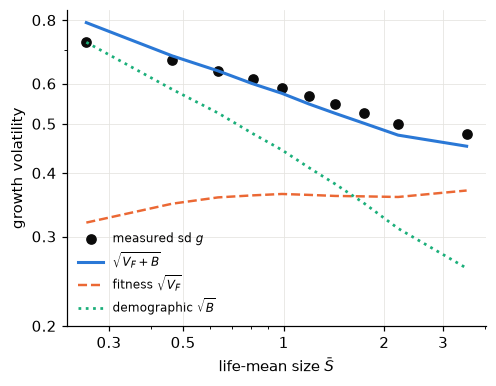

In [4]:
rows = eco.decomposition("powerlaw")
P = np.array_split(np.argsort(rows[:, 0]), 10)
tab = np.array([(m[0], np.sqrt(m[1]), np.sqrt(m[2] + m[3]), np.sqrt(m[2]), np.sqrt(m[3])) for m in (rows[p].mean(0) for p in P)])
print(f"{len(rows)} lives with >= 20 growth rates")
print(f"{'Sbar':>6} | {'sd g':>6} | sqrt(V_F+B) | ratio | sqrt V_F  sqrt B")
for r in tab:
    print(f"{r[0]:6.2f} | {r[1]:6.3f} | {r[2]:11.3f} | {r[2] / r[1]:5.2f} | {r[3]:8.3f} {r[4]:7.3f}")
lx = np.log(tab[:, 0])
print(f"slope of sd g against Sbar: measured {-np.polyfit(lx, np.log(tab[:, 1]), 1)[0]:.3f}, "
      f"predicted {-np.polyfit(lx, np.log(tab[:, 2]), 1)[0]:.3f}")
cross = np.flatnonzero(np.diff(np.sign(tab[:, 4] - tab[:, 3])))
print(f"floor and noise are equal between Sbar = {tab[cross[0], 0]:.2f} and {tab[cross[0] + 1, 0]:.2f}")

fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.loglog(tab[:, 0], tab[:, 1], "o", color="#0b0b0b", ms=6, label="measured sd $g$")
ax.loglog(tab[:, 0], tab[:, 2], "-", color="#2a78d6", lw=2, label=r"$\sqrt{V_F+B}$")
ax.loglog(tab[:, 0], tab[:, 3], "--", color="#eb6834", lw=1.6, label=r"fitness $\sqrt{V_F}$")
ax.loglog(tab[:, 0], tab[:, 4], ":", color="#1baf7a", lw=1.8, label=r"demographic $\sqrt{B}$")
ax.set(xlabel=r"life-mean size $\bar S$", ylabel="growth volatility")
tidy(ax, [0.3, 0.5, 1, 2, 3], [0.2, 0.3, 0.4, 0.5, 0.6, 0.8])
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "demographic_volatility_law.png", dpi=200)

The law reproduces the measured volatility to within $5\%$ over a decade and a half of $\bar S$, and $9\%$ in the lowest decile,
where the linearisation of the noise around the noise-free path is worst.

**A crossover.** The fitness part is nearly flat in size, $\sqrt{V_F}\simeq0.32$–$0.37$: competition moves established firms by
about the same relative amount whatever their size. The demographic part falls as $\bar S^{-b/2}$ with $b=0.66$–$0.87$
(notebook 05; $b=1$ for $B\simeq D\Delta t/\bar S$). So

$$v^2\simeq v_F^2+B(\bar S)$$

is a crossover from a steep decline, where noise dominates, to slope $0$, where the floor does; the two parts are equal at
$\bar S\simeq1.5$. The decomposition has the two-regime shape reported for French firms that include very small ones
(Fontanelli et al. 2025), but the measured life panel does not resolve the two regimes: its local slopes by size fifth are
$0.26$, $0.17$, $0.14$, $0.23$, $0.27$ (production run, notebook 06). **$\zeta_1\simeq0.2$ is the effective slope of the whole range**. The crossover scale grows with
$D$, and so does the effective exponent (notebook 06: $\zeta_1=0.20$, $0.23$, $0.25$ for $D=0.1$, $0.15$, $0.2$ at
$\sigma=1.70$).

**Without the filter.** If a firm followed its field exactly it would sit on the plateau $S=\Phi$, and its growth variance would
be $\operatorname{Var}(\Delta\ln\Phi)$ plus the unfiltered noise $D\Delta t\langle S^{-1}\rangle$. Per life, over the steps where the field is
positive (it is not for 7% of the samples of the largest firms and 36% of the smallest):

In [5]:
def unfiltered(path=DATA / "demographic" / "volatility_law_unfiltered.npz"):
    """(Sbar, var g, Var(Delta ln Phi) over steps with Phi > 0, D dt <1/S>) for every life with >= 20 growth rates."""
    if not path.exists():
        rows = []
        for seed in eco.SEEDS:
            S, L, _, _, Phi = eco.reference_economy(seed)
            T = S.shape[1]
            for i in range(S.shape[0]):
                for seg in np.split(np.arange(T), np.flatnonzero(np.diff(L[i])) + 1):
                    if seg.size < 21:
                        continue
                    x, ph = S[i, seg], Phi[i, seg]
                    pos = ph > 0
                    dl = np.diff(np.log(np.where(pos, ph, 1.0)))[pos[1:] & pos[:-1]]
                    rows.append((x.mean(), np.diff(np.log(x)).var(), dl.var() if dl.size > 3 else np.nan,
                                 eco.D * eco.DT * np.mean(1 / x[:-1])))
        np.savez(path, rows=np.array(rows))
    return np.load(path)["rows"]


u = unfiltered()
P = np.array_split(np.argsort(u[:, 0]), 10)
tu = np.array([(u[p, 0].mean(), np.sqrt(u[p, 1].mean()), np.sqrt(np.nanmean(u[p, 2])), np.sqrt(u[p, 3].mean())) for p in P])
print(f"{'Sbar':>6} | {'sd g':>6} | unfiltered | ratio | sqrt Var dlnPhi  sqrt(D dt<1/S>) | filtered sqrt V_F  sqrt B")
for r, f in zip(tu, tab):
    print(f"{r[0]:6.2f} | {r[1]:6.3f} | {np.hypot(r[2], r[3]):10.3f} | {np.hypot(r[2], r[3]) / r[1]:5.2f} | "
          f"{r[2]:15.3f} {r[3]:16.3f} | {f[3]:17.3f} {f[4]:6.3f}")
lu = np.log(tu[:, 0])
print(f"slope of sd g against Sbar: measured {-np.polyfit(lu, np.log(tu[:, 1]), 1)[0]:.3f}, "
      f"unfiltered {-np.polyfit(lu, np.log(np.hypot(tu[:, 2], tu[:, 3])), 1)[0]:.3f}")

  Sbar |   sd g | unfiltered | ratio | sqrt Var dlnPhi  sqrt(D dt<1/S>) | filtered sqrt V_F  sqrt B
  0.26 |  0.726 |      1.158 |  1.59 |           0.897            0.733 |             0.320  0.724
  0.46 |  0.668 |      0.986 |  1.48 |           0.786            0.595 |             0.349  0.585
  0.64 |  0.636 |      0.900 |  1.42 |           0.723            0.536 |             0.359  0.526
  0.81 |  0.613 |      0.835 |  1.36 |           0.676            0.490 |             0.362  0.479
  0.99 |  0.589 |      0.785 |  1.33 |           0.639            0.457 |             0.364  0.445
  1.19 |  0.568 |      0.735 |  1.29 |           0.601            0.423 |             0.363  0.411
  1.43 |  0.547 |      0.691 |  1.26 |           0.568            0.394 |             0.361  0.381
  1.73 |  0.525 |      0.644 |  1.22 |           0.531            0.363 |             0.360  0.350
  2.20 |  0.500 |      0.590 |  1.18 |           0.492            0.326 |             0.359  0.312
  3.53 | 

The unfiltered law overestimates the volatility by a factor $1.6$ in the smallest decile, falling to $1.1$ in the largest, and doubles
the slope. The noise part hardly changes ($\sqrt{D\Delta t\langle S^{-1}\rangle}$ is within 6% of $\sqrt B$ at $\Delta t=0.5$); the excess is the field:
$\sqrt{\operatorname{Var}\Delta\ln\Phi}$ falls from $0.9$ to $0.44$ with size, while the floor $\sqrt{V_F}$ is flat at $0.32$–$0.37$. **A firm does not
follow the fast part of its field**, and least of all a small firm, whose field is low and therefore large in relative terms.